# 2 — Young vs old: random forest

Can a forest combine the features into a classifier that beats guessing?

**"Guessing" is three different numbers here, and picking the wrong one is the main way to
fool yourself:**

| baseline | value | what it means |
|---|---|---|
| ROC AUC null | **0.500** | ranks a random old/young pair correctly half the time |
| balanced accuracy null | **0.500** | average of the two per-class recalls, for any constant answer |
| raw accuracy null | **0.629** | always answer "old" — 219 of 348 clusters are old |

A classifier at 0.63 raw accuracy has learned **nothing**. The headline metrics below are
therefore AUC and balanced accuracy, with raw accuracy shown only beside its own baseline.

**And 0.5 is not the real bar either.** MW is 73% old, SMC 70%, LMC 47%, so a classifier
given only galaxy and observing setup already scores well above 0.5. The question this
notebook answers is whether the *light curves* add anything to that — same nested comparison
as the regression, same cluster-grouped splits, same held-out clusters.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import binary_utils as B
A = B.A                                  # the shared module from ../analysis_utils.py

GT = '/astro/users/cgwill/TESS_Cluster_Age_ML/GenerateTable_CGW/data'
CANDIDATES = [f'{GT}/cluster_table_Sep23_all_combos_le3sectors.pkl',
              f'{GT}/cluster_table_Sep21_3sectorcombos_real_nofallback.pkl']
TABLE = next(p for p in CANDIDATES if os.path.exists(p))
SEED = 0
print('using', os.path.basename(TABLE), '| split at log age =', B.AGE_SPLIT)
pd.set_option('display.width', 220)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (roc_auc_score, balanced_accuracy_score, accuracy_score,
                             confusion_matrix, roc_curve, brier_score_loss)
N_SPLITS = 5

using cluster_table_Sep23_all_combos_le3sectors.pkl | split at log age = 8.0


In [2]:
rows = A.load_rows(TABLE)
meta = A.cluster_metadata()
clusters = A.cluster_table(rows, meta=meta)
clusters = clusters[clusters.age.notna()].reset_index(drop=True)

y = B.make_label(clusters.age).astype(int)
FEATURES  = [c for c, _, _ in A.feature_columns(rows)]
NUISANCES = [n for n, _, _ in A.NUISANCE_SPEC if n in clusters.columns]
base = B.class_baselines(y)

print(f"{base['n']} clusters: {base['n_young']} young, {base['n_old']} old "
      f"({base['frac_old']:.1%} old)")
print(f"  always-answer-'old' accuracy : {base['majority_accuracy']:.3f}   <- the accuracy null")
print(f"  balanced accuracy / AUC null : 0.500                <- the '50% guessing' null")
ct = pd.crosstab(clusters.origin, pd.Series(y).map(B.LABELS))
ct['frac old'] = (ct[B.LABELS[1]] / ct.sum(axis=1)).round(3)
display(ct)
print('Galaxy alone separates the classes, so every result below is judged against a')
print('nuisance-only model, not against 0.5.')

17233 rows, 348 clusters from cluster_table_Sep23_all_combos_le3sectors.pkl
rows per cluster: median 3, max 409


348 clusters: 129 young, 219 old (62.9% old)
  always-answer-'old' accuracy : 0.629   <- the accuracy null
  balanced accuracy / AUC null : 0.500                <- the '50% guessing' null


col_0,old (≥10⁸ yr),young (<10⁸ yr),frac old
origin,,,
LMC,55,63,0.466
MW,90,34,0.726
SMC,74,32,0.698


Galaxy alone separates the classes, so every result below is judged against a
nuisance-only model, not against 0.5.


## 1 · Splits

Whole clusters, stratified on the binary label, with the 20% holdout scored once at the end.
Same seed and the same `holdout_by_cluster` as the regression notebooks.

In [3]:
groups = clusters.name.values
HOLD, FOLD = B.holdout_and_folds(groups, y, frac=0.2, n_splits=N_SPLITS, seed=SEED)
POOL = ~HOLD

X_nuis = A.design_matrix(clusters, NUISANCES, add_const=False)
X_feat = clusters[FEATURES].apply(pd.to_numeric, errors='coerce')
X_full = pd.concat([X_nuis, X_feat], axis=1)

print(f'pool    {POOL.sum():3d} clusters  ({y[POOL].mean():.1%} old)')
print(f'holdout {HOLD.sum():3d} clusters  ({y[HOLD].mean():.1%} old)')
for k in range(N_SPLITS):
    m = FOLD == k
    print(f'  fold {k}: {m.sum():3d} clusters, {y[m].mean():.1%} old')
assert not (set(groups[POOL]) & set(groups[HOLD]))
print('no cluster spans the holdout boundary — verified')

pool    278 clusters  (62.9% old)
holdout  70 clusters  (62.9% old)
  fold 0:  56 clusters, 69.6% old
  fold 1:  56 clusters, 57.1% old
  fold 2:  56 clusters, 66.1% old
  fold 3:  55 clusters, 58.2% old
  fold 4:  55 clusters, 63.6% old
no cluster spans the holdout boundary — verified


## 2 · Nested comparison

`class_weight='balanced'` so the forest is not rewarded for always answering "old"; that
makes balanced accuracy and AUC the coherent metrics to read.

In [4]:
def make_clf(seed=SEED):
    return Pipeline([('impute', SimpleImputer(strategy='median')),
                     ('rf', RandomForestClassifier(n_estimators=600, min_samples_leaf=3,
                                                   max_features='sqrt', class_weight='balanced',
                                                   random_state=seed, n_jobs=8))])

def cv_predict(X, y_vec, fold, seed=SEED):
    """Out-of-fold probabilities over the CV pool; -1 folds (the holdout) are left NaN."""
    p = np.full(len(y_vec), np.nan)
    for k in range(N_SPLITS):
        tr, te = (fold != k) & (fold >= 0), fold == k
        if not te.any():
            continue
        m = make_clf(seed + k).fit(X[tr], y_vec[tr])
        p[te] = m.predict_proba(X[te])[:, 1]
    return p

def score(y_true, prob, thresh=0.5):
    pred = (prob >= thresh).astype(int)
    return dict(auc=roc_auc_score(y_true, prob),
                balanced_acc=balanced_accuracy_score(y_true, pred),
                accuracy=accuracy_score(y_true, pred),
                brier=brier_score_loss(y_true, prob))

SETS = {'nuisance-only': X_nuis, 'features-only': X_feat, 'full': X_full}
oof, results = {}, []
for label, X in SETS.items():
    p = cv_predict(X, y, FOLD)
    oof[label] = p
    m = np.isfinite(p)
    results.append(dict(model=label, n_cols=X.shape[1], **score(y[m], p[m])))
res = pd.DataFrame(results)
display(res.round(3))

maj = base['majority_accuracy']
print(f"nulls:  AUC 0.500 | balanced accuracy 0.500 | raw accuracy {maj:.3f}")
d_auc = res.loc[res.model == 'full', 'auc'].iloc[0] - res.loc[res.model == 'nuisance-only', 'auc'].iloc[0]
print(f'\nfull − nuisance-only:  dAUC = {d_auc:+.3f}   <- the quantity of interest')

,model,n_cols,auc,balanced_acc,accuracy,brier
0,nuisance-only,10,0.740,0.655,0.669,0.199
1,features-only,23,0.699,0.646,0.662,0.213
2,full,33,0.736,0.666,0.687,0.196


nulls:  AUC 0.500 | balanced accuracy 0.500 | raw accuracy 0.629

full − nuisance-only:  dAUC = -0.004   <- the quantity of interest


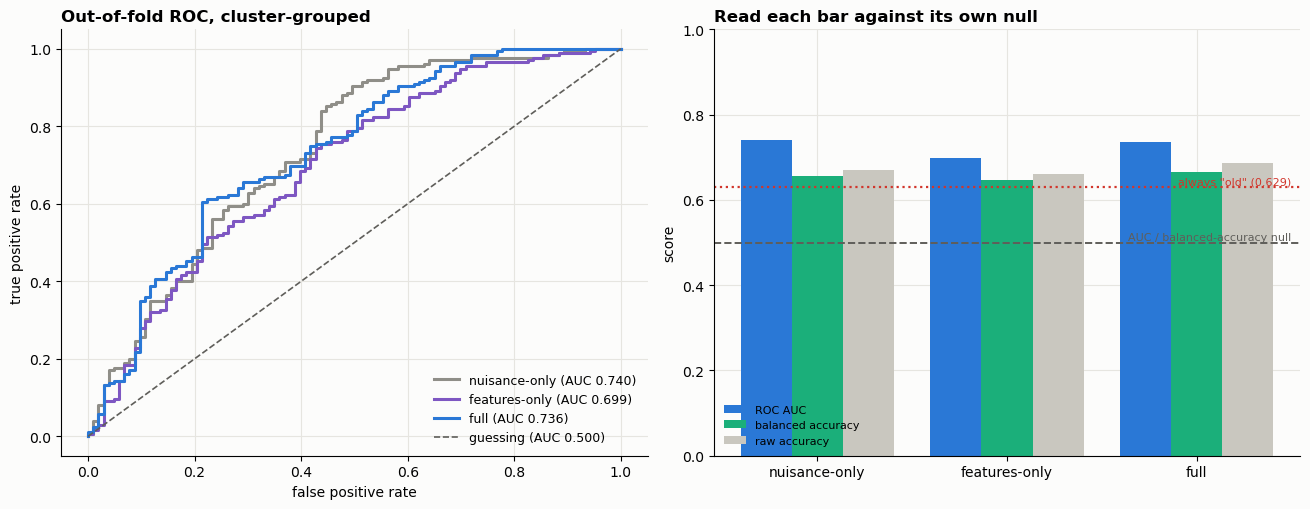

CONCLUSION —
  Full model: AUC 0.736, balanced accuracy 0.666, raw accuracy 0.687 (vs 0.629 for always answering "old").
  Nuisance-only: AUC 0.740. The light curves move AUC by -0.004.
  The full model beats guessing, but so does the nuisance-only model, and the gap
  between them is negligible — the separation is galaxy and observing setup, not age.


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13.2, 5.2))
cols = {'nuisance-only': '#8f8e88', 'features-only': '#7e57c2', 'full': '#2a78d6'}
for label, p in oof.items():
    m = np.isfinite(p)
    fpr, tpr, _ = roc_curve(y[m], p[m])
    axs[0].plot(fpr, tpr, lw=2.2, color=cols[label],
                label=f'{label} (AUC {roc_auc_score(y[m], p[m]):.3f})')
axs[0].plot([0, 1], [0, 1], '--', color='#5f5e5a', lw=1.2, label='guessing (AUC 0.500)')
axs[0].set(xlabel='false positive rate', ylabel='true positive rate')
axs[0].set_title('Out-of-fold ROC, cluster-grouped', loc='left', fontweight='bold')
axs[0].legend(fontsize=9, loc='lower right')

t = res.set_index('model')
x = np.arange(len(t)); w = 0.27
axs[1].bar(x - w, t.auc, w, color='#2a78d6', label='ROC AUC')
axs[1].bar(x, t.balanced_acc, w, color='#1baf7a', label='balanced accuracy')
axs[1].bar(x + w, t.accuracy, w, color='#c9c7bf', label='raw accuracy')
axs[1].axhline(0.5, color='#5f5e5a', ls='--', lw=1.4)
axs[1].text(len(t) - .5, 0.505, 'AUC / balanced-accuracy null', fontsize=8, ha='right',
            color='#5f5e5a')
axs[1].axhline(maj, color='#d1352b', ls=':', lw=1.6)
axs[1].text(len(t) - .5, maj + .005, f'always "old" ({maj:.3f})', fontsize=8, ha='right',
            color='#d1352b')
axs[1].set_xticks(x, list(t.index))
axs[1].set(ylim=(0, 1.0), ylabel='score')
axs[1].set_title('Read each bar against its own null', loc='left', fontweight='bold')
axs[1].legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.show()

f = t.loc['full']; n = t.loc['nuisance-only']
print('CONCLUSION —')
print(f'  Full model: AUC {f.auc:.3f}, balanced accuracy {f.balanced_acc:.3f}, '
      f'raw accuracy {f.accuracy:.3f} (vs {maj:.3f} for always answering "old").')
print(f'  Nuisance-only: AUC {n.auc:.3f}. The light curves move AUC by {f.auc - n.auc:+.3f}.')
if f.auc < 0.55:
    print('  The full model is barely above guessing: the features do not separate young from')
    print('  old at this cut.')
elif f.auc - n.auc < 0.02:
    print('  The full model beats guessing, but so does the nuisance-only model, and the gap')
    print('  between them is negligible — the separation is galaxy and observing setup, not age.')
else:
    print('  The light curves add real separation beyond the nuisances; §3 tests whether the')
    print('  gap survives a label permutation.')

## 3 · Is the gain more than chance?

Labels are shuffled **within galaxy**, so the null keeps the galaxy–age association intact and
asks only whether the light curves add anything. The capacity effect matters here just as in
the regression: adding 23 columns raises the score a little even on shuffled labels, and the
null measures exactly that.

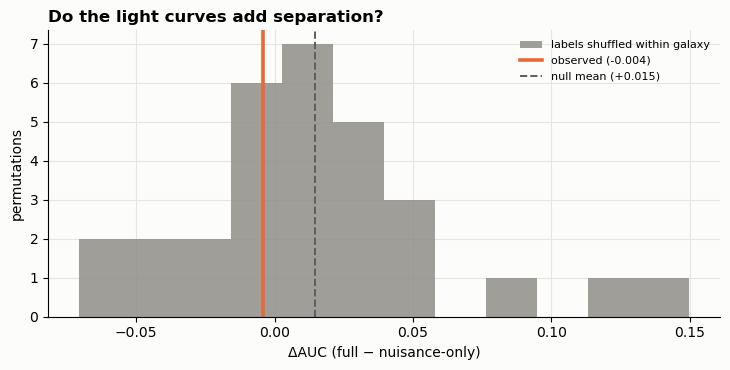

CONCLUSION —
  Observed dAUC -0.004 vs null +0.015 +/- 0.048, p = 0.774.
  Note the null mean is +0.015, not zero: that is pure model capacity from
  adding 23 columns. Any gain below it is not evidence of anything.
  The gain does not clear the null — no detectable light-curve separation.


In [6]:
N_PERM = 30
rng = np.random.default_rng(SEED)

def delta_auc(y_vec):
    a = cv_predict(X_nuis, y_vec, FOLD); b = cv_predict(X_full, y_vec, FOLD)
    m = np.isfinite(a) & np.isfinite(b)
    return roc_auc_score(y_vec[m], b[m]) - roc_auc_score(y_vec[m], a[m])

obs = delta_auc(y)
null = []
for i in range(N_PERM):
    yp = y.copy()
    for o in clusters.origin.unique():
        idx = np.where((clusters.origin.values == o) & POOL)[0]
        yp[idx] = rng.permutation(y[idx])
    null.append(delta_auc(yp))
null = np.array(null)
p_val = (np.sum(null >= obs) + 1) / (len(null) + 1)

fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.hist(null, bins=12, color='#8f8e88', alpha=.85, label='labels shuffled within galaxy')
ax.axvline(obs, color='#eb6834', lw=2.6, label=f'observed ({obs:+.3f})')
ax.axvline(null.mean(), color='#5f5e5a', lw=1.4, ls='--',
           label=f'null mean ({null.mean():+.3f})')
ax.set(xlabel='ΔAUC (full − nuisance-only)', ylabel='permutations')
ax.set_title('Do the light curves add separation?', loc='left', fontweight='bold')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

print('CONCLUSION —')
print(f'  Observed dAUC {obs:+.3f} vs null {null.mean():+.3f} +/- {null.std():.3f}, p = {p_val:.3f}.')
if null.mean() > 0.005:
    print(f'  Note the null mean is {null.mean():+.3f}, not zero: that is pure model capacity from')
    print('  adding 23 columns. Any gain below it is not evidence of anything.')
print('  ' + ('The gain clears the null.' if p_val < 0.05 else
      'The gain does not clear the null — no detectable light-curve separation.'))

## 4 · Which families the forest used

Block permutation on the out-of-fold AUC: a whole family is shuffled at once, because
permuting one member of a correlated pair changes nothing while its twin still carries the
information.

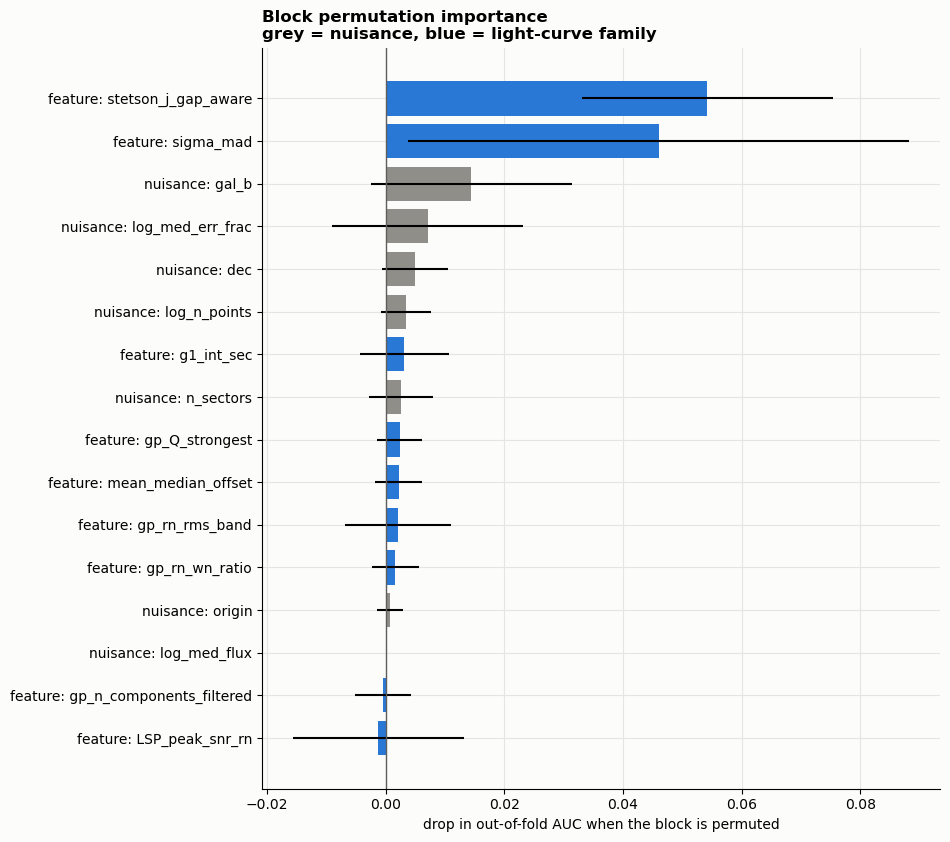

CONCLUSION —
  Light-curve families above their own fold scatter: stetson_j_gap_aware, sigma_mad.
  Summed AUC importance — light curve +0.0963 vs nuisance +0.0296.


In [7]:
from collections import defaultdict
reliability = A.feature_reliability(rows)
families = A.feature_families(clusters, FEATURES, threshold=0.8, reliability=reliability)
FAMILY_OF = families.set_index('feature').family.to_dict()

def blocks_of(columns):
    out = defaultdict(list)
    for c in columns:
        if c in FAMILY_OF:              out[f'feature: {FAMILY_OF[c]}'].append(c)
        elif c.startswith('origin_'):   out['nuisance: origin'].append(c)
        else:                           out[f'nuisance: {c}'].append(c)
    return dict(out)

BLOCKS = blocks_of(X_full.columns)
rng = np.random.default_rng(SEED)
imp = defaultdict(list)
for k in range(N_SPLITS):
    tr, te = (FOLD != k) & (FOLD >= 0), FOLD == k
    if not te.any():
        continue
    m = make_clf(SEED + k).fit(X_full[tr], y[tr])
    Xte, yte = X_full[te], y[te]
    b = roc_auc_score(yte, m.predict_proba(Xte)[:, 1])
    for name, colset in BLOCKS.items():
        d = []
        for _ in range(6):
            Xp = Xte.copy()
            Xp[colset] = Xp[colset].to_numpy()[rng.permutation(len(Xp))]
            d.append(b - roc_auc_score(yte, m.predict_proba(Xp)[:, 1]))
        imp[name].append(np.mean(d))

impdf = pd.DataFrame({'block': list(imp), 'importance': [np.mean(v) for v in imp.values()],
                      'sd': [np.std(v) for v in imp.values()]})
impdf['kind'] = np.where(impdf.block.str.startswith('feature'), 'light curve', 'nuisance')
impdf = impdf.sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(9.6, 0.42 * min(len(impdf), 16) + 1.8))
t = impdf.head(16).iloc[::-1]
ax.barh(t.block, t.importance, xerr=t.sd,
        color=np.where(t.kind == 'nuisance', '#8f8e88', '#2a78d6'))
ax.axvline(0, color='#5f5e5a', lw=1)
ax.set(xlabel='drop in out-of-fold AUC when the block is permuted')
ax.set_title('Block permutation importance\ngrey = nuisance, blue = light-curve family',
             loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

lc, nu = impdf[impdf.kind == 'light curve'], impdf[impdf.kind == 'nuisance']
pos = lc[lc.importance > lc.sd]
print('CONCLUSION —')
print(f'  Light-curve families above their own fold scatter: '
      f'{", ".join(pos.block.str.replace("feature: ", "", regex=False)) or "none"}.')
print(f'  Summed AUC importance — light curve {lc.importance.sum():+.4f} vs '
      f'nuisance {nu.importance.sum():+.4f}.')

## 5 · The one look at the held-out clusters

Trained on the pool, scored once on the 20% of clusters set aside at the start.

,model,auc,balanced_acc,accuracy,brier
0,nuisance-only,0.681,0.637,0.643,0.225
1,features-only,0.767,0.733,0.743,0.187
2,full,0.797,0.733,0.743,0.177


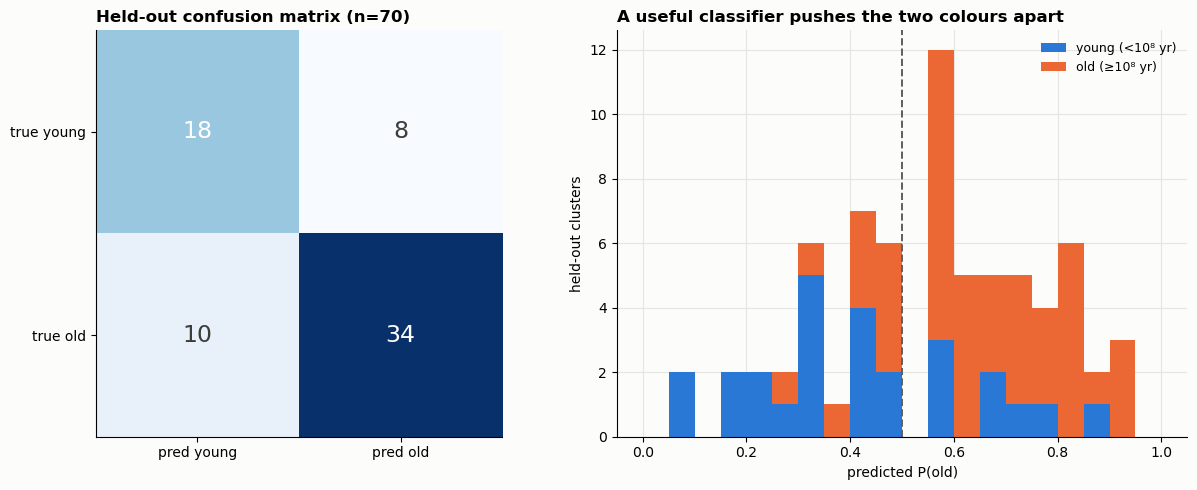

CONCLUSION —
  Held out: full AUC 0.797, balanced accuracy 0.733, raw accuracy 0.743 (always-"old" = 0.629).
  Nuisance-only on the same clusters: AUC 0.681.
  dAUC on the holdout +0.116 vs -0.004 on the CV pool.
  With 70 clusters the 95% CI on an AUC near 0.5 is roughly +/-0.07, so treat
  a gap smaller than that as noise.
  ANSWER TO THE QUESTION: a forest that had learned nothing would sit at AUC 0.500 and
  balanced accuracy 0.500. This one sits at 0.797 / 0.733.


In [8]:
hold_rows, prob_h = [], {}
for label, X in SETS.items():
    m = make_clf(SEED).fit(X[POOL], y[POOL])
    ph = m.predict_proba(X[HOLD])[:, 1]
    prob_h[label] = ph
    hold_rows.append(dict(model=label, **score(y[HOLD], ph)))
hold = pd.DataFrame(hold_rows)
display(hold.round(3))

ph = prob_h['full']
pred = (ph >= 0.5).astype(int)
cm = confusion_matrix(y[HOLD], pred)
fig, axs = plt.subplots(1, 2, figsize=(12.6, 5.0))
im = axs[0].imshow(cm, cmap='Blues')
axs[0].set_xticks([0, 1], ['pred young', 'pred old'])
axs[0].set_yticks([0, 1], ['true young', 'true old'])
for i in range(2):
    for j in range(2):
        axs[0].text(j, i, cm[i, j], ha='center', va='center', fontsize=17,
                    color='white' if cm[i, j] > cm.max() / 2 else '#3d3d39')
axs[0].grid(False)
axs[0].set_title(f'Held-out confusion matrix (n={HOLD.sum()})', loc='left', fontweight='bold')

bins = np.linspace(0, 1, 21)
axs[1].hist([ph[y[HOLD] == 0], ph[y[HOLD] == 1]], bins=bins, stacked=True,
            color=[B.COLOURS[0], B.COLOURS[1]], label=[B.LABELS[0], B.LABELS[1]])
axs[1].axvline(0.5, color='#5f5e5a', ls='--', lw=1.4)
axs[1].set(xlabel='predicted P(old)', ylabel='held-out clusters')
axs[1].set_title('A useful classifier pushes the two colours apart', loc='left',
                 fontweight='bold')
axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

h = hold.set_index('model')
print('CONCLUSION —')
print(f'  Held out: full AUC {h.loc["full", "auc"]:.3f}, balanced accuracy '
      f'{h.loc["full", "balanced_acc"]:.3f}, raw accuracy {h.loc["full", "accuracy"]:.3f} '
      f'(always-"old" = {maj:.3f}).')
print(f'  Nuisance-only on the same clusters: AUC {h.loc["nuisance-only", "auc"]:.3f}.')
print(f'  dAUC on the holdout {h.loc["full", "auc"] - h.loc["nuisance-only", "auc"]:+.3f} '
      f'vs {d_auc:+.3f} on the CV pool.')
print(f'  With {HOLD.sum()} clusters the 95% CI on an AUC near 0.5 is roughly +/-0.07, so treat')
print('  a gap smaller than that as noise.')
print('  ANSWER TO THE QUESTION: a forest that had learned nothing would sit at AUC 0.500 and')
print(f'  balanced accuracy 0.500. This one sits at {h.loc["full", "auc"]:.3f} / '
      f'{h.loc["full", "balanced_acc"]:.3f}.')

## 6 · Result table

In [9]:
res.assign(split='cv_pool').to_csv('results_rf_classification_cv.csv', index=False)
hold.assign(split='holdout').to_csv('results_rf_classification_holdout.csv', index=False)
impdf.to_csv('results_rf_classification_importances.csv', index=False)
print('wrote results_rf_classification_cv.csv, results_rf_classification_holdout.csv,')
print('      results_rf_classification_importances.csv')
print()
print('CONCLUSION —')
print(f'  Binary cut at 10^8 yr, {base["n_young"]} young vs {base["n_old"]} old clusters.')
print(f'  CV pool : full AUC {res.set_index("model").loc["full", "auc"]:.3f}, '
      f'nuisance-only {res.set_index("model").loc["nuisance-only", "auc"]:.3f}')
print(f'  Holdout : full AUC {h.loc["full", "auc"]:.3f}, '
      f'nuisance-only {h.loc["nuisance-only", "auc"]:.3f}')
print(f'  Permutation p on dAUC = {p_val:.3f}.')
print('  Compare with the regression: ../results_random_forest.csv. If the classification')
print('  separates the extremes while the regression R2 stayed near zero, the information is')
print('  in the tails, not in the middle of the age range.')

wrote results_rf_classification_cv.csv, results_rf_classification_holdout.csv,
      results_rf_classification_importances.csv

CONCLUSION —
  Binary cut at 10^8 yr, 129 young vs 219 old clusters.
  CV pool : full AUC 0.736, nuisance-only 0.740
  Holdout : full AUC 0.797, nuisance-only 0.681
  Permutation p on dAUC = 0.774.
  Compare with the regression: ../results_random_forest.csv. If the classification
  separates the extremes while the regression R2 stayed near zero, the information is
  in the tails, not in the middle of the age range.
